# Notebook 03a — Embedder: HOG + Colour Histogram (classical)

**Purpose:** a DINOv2 alternative with no learning at all – hand-engineered features for shape/texture (HOG)
and colour (HSV histogram) – evaluated on FoodSeg103 food regions with cosine KNN.

---

## 1. What Makes a Good Food Embedding?

For dish recognition by visual similarity, we want features that capture:
- **Shape** — round vs square, domed vs flat
- **Colour** — red curry vs green curry
- **Texture** — smooth (soup) vs granular (rice) vs stringy (noodles)

DINOv2 learns all three implicitly. A classical alternative must be explicit about each.

## 2. HOG + Colour Histogram

**HOG (Histogram of Oriented Gradients)** — Dalal & Triggs, CVPR 2005:
1. Divide image into cells (here 16×16 pixels)
2. Compute gradient magnitude and direction at each pixel
3. Build a histogram of gradient orientations in each cell (9 bins)
4. Normalise histograms within overlapping blocks (2×2 cells)
5. Concatenate all block descriptors → fixed-length vector

HOG captures **edge structure** = shape and texture.

**Colour Histogram:** quantise the region's pixels into a grid of HSV colour bins and count them.
Captures **colour distribution**, independent of where the colour is. Only pixels inside the food mask are counted,
so the zeroed background does not dominate the histogram.

Each part is L2-normalised before concatenation, so neither dominates just because of its scale
(`COLOUR_WEIGHT` controls the balance).

## Evaluation protocol (shared by notebooks 03a, 03b, 03c)

Every food-class region of a FoodSeg103 annotation with area ≥ 32×32 px becomes one sample:
bounding-box crop, background pixels zeroed, label = its FoodSeg103 class (103 classes).

- **Gallery** = all train-split regions ("enrolled" dishes), **queries** = test-split regions.
- Each query is matched to the gallery by **cosine similarity** (vectors are L2-normalised), exactly like the
  dish database lookup.
- Metrics (`foodseg_embed.knn_evaluate`): similarity-weighted **KNN accuracy** for K = 1, 3, 5, 10;
  **top-5 hit** (the right class is among the 5 nearest neighbours); **macro accuracy** (1-NN accuracy averaged over
  classes – FoodSeg103 is very imbalanced, so this is the fairer number).
- Results are written to `outputs/embed/<embedder>_test.json`; notebook 03c puts all of them in one table.

## 3. Library & configuration

In [6]:
import time, json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import foodseg_common as fc
import foodseg_embed as fe

print('OpenCV:', cv2.__version__)

OpenCV: 4.13.0


In [7]:
CROP_SIZE     = 128          # crops are resized to CROP_SIZE x CROP_SIZE before feature extraction
HOG_CELL      = 16
HOG_BLOCK     = 2
HOG_BINS      = 9
COLOR_BINS    = (8, 8, 8)    # H, S, V bins
COLOUR_WEIGHT = 1.0          # weight of the colour part relative to HOG
RAW_SIZE      = 32           # raw-pixel baseline resolution

TRAIN_LIMIT = None           # number of images (None = full split); e.g. 200 for a quick trial
TEST_LIMIT  = None

NAMES = fe.category_names()
train_regions = fe.region_index('train', limit=TRAIN_LIMIT)
test_regions  = fe.region_index('test',  limit=TEST_LIMIT)
train_y, test_y = fe.labels_of(train_regions), fe.labels_of(test_regions)
print(f'gallery (train) regions: {len(train_regions)}  classes: {len(np.unique(train_y))}')
print(f'query   (test)  regions: {len(test_regions)}  classes: {len(np.unique(test_y))}')

gallery (train) regions: 17982  classes: 103
query   (test)  regions: 3887  classes: 99


## 4. HOG + colour embedder

In [8]:
class HOGColourEmbedder:
    """
    Classical image embedder: HOG (shape/texture) + HSV histogram (colour).
    No neural network. Works on CPU. Deterministic output.
    """

    def __init__(self, image_size=128, hog_cell=16, hog_block=2, hog_bins=9,
                 color_bins=(8, 8, 8), colour_weight=1.0):
        self.image_size = image_size
        self.color_bins = color_bins
        self.colour_weight = colour_weight

        # OpenCV HOG descriptor over the whole (square) crop
        win_size     = (image_size, image_size)
        block_size   = (hog_block * hog_cell, hog_block * hog_cell)
        block_stride = (hog_cell, hog_cell)
        cell_size    = (hog_cell, hog_cell)
        self.hog = cv2.HOGDescriptor(win_size, block_size, block_stride, cell_size, hog_bins)

        self.hog_dim = self.hog.getDescriptorSize()
        self.colour_dim = int(np.prod(color_bins))
        print(f'[HOGColourEmbedder] HOG dim={self.hog_dim}, Colour dim={self.colour_dim}, '
              f'Total={self.output_dim}')

    @property
    def output_dim(self):
        return self.hog_dim + self.colour_dim

    def hog_features(self, rgb):
        """Gradient-orientation histograms of the grey crop (shape + texture)."""
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        return self.hog.compute(gray).ravel()

    def colour_features(self, rgb, mask=None):
        """HSV histogram of the pixels inside mask, as a distribution (sums to 1)."""
        # HSV separates colour (H) from brightness (V), so lighting changes mostly affect V
        hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
        hist = cv2.calcHist([hsv], [0, 1, 2], mask, list(self.color_bins), [0, 180, 0, 256, 0, 256]).ravel()
        return hist / max(hist.sum(), 1.0)

    def combine(self, hog_vec, colour_vec):
        """L2-normalise each part, weight, concatenate, L2-normalise."""
        h = fe.l2_normalise(np.atleast_2d(hog_vec))
        c = fe.l2_normalise(np.atleast_2d(colour_vec)) * self.colour_weight
        return fe.l2_normalise(np.concatenate([h, c], axis=1))

    def embed(self, rgb, mask=None):
        """Embedding of one crop (RGB uint8, image_size x image_size), shape (output_dim,)."""
        return self.combine(self.hog_features(rgb), self.colour_features(rgb, mask))[0]


embedder = HOGColourEmbedder(CROP_SIZE, HOG_CELL, HOG_BLOCK, HOG_BINS, COLOR_BINS, COLOUR_WEIGHT)

[HOGColourEmbedder] HOG dim=1764, Colour dim=512, Total=2276


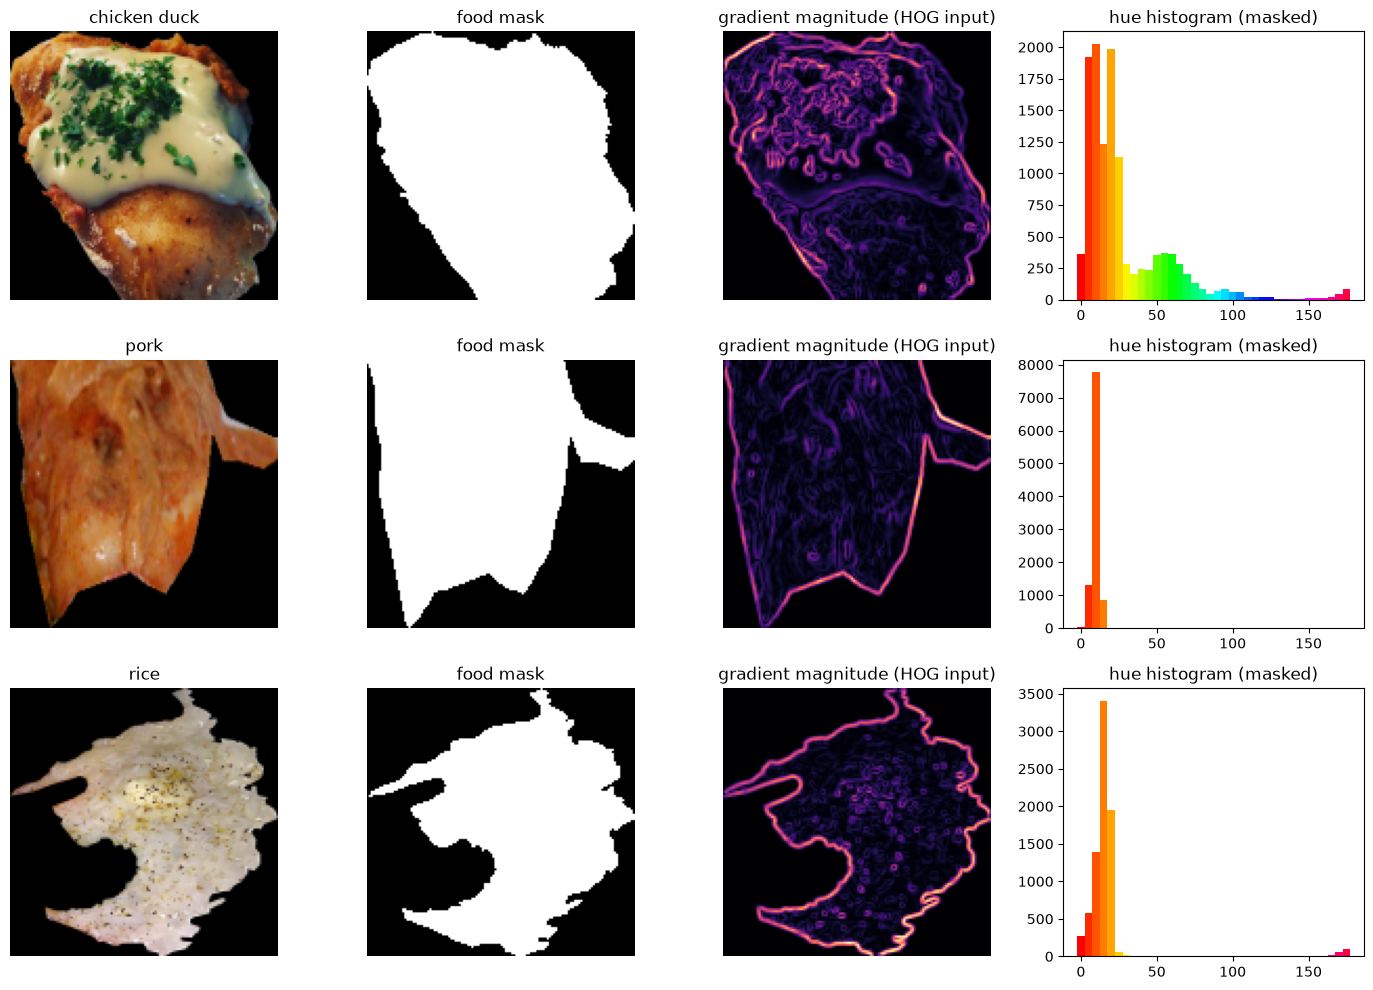

In [9]:
# A few gallery crops with their HOG gradient image and hue histogram
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for row, i in zip(axes, np.linspace(0, len(train_regions) - 1, 4, dtype=int)[:3]):
    (_, crop, m), = list(fe.iter_crops('train', [train_regions[i]], CROP_SIZE))
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY).astype(np.float32)
    mag = np.hypot(cv2.Sobel(gray, cv2.CV_32F, 1, 0), cv2.Sobel(gray, cv2.CV_32F, 0, 1))
    hue = cv2.calcHist([cv2.cvtColor(crop, cv2.COLOR_RGB2HSV)], [0], m, [36], [0, 180]).ravel()
    row[0].imshow(crop); row[0].set_title(NAMES[train_regions[i][1]]); row[0].axis('off')
    row[1].imshow(m, cmap='gray'); row[1].set_title('food mask'); row[1].axis('off')
    row[2].imshow(mag, cmap='magma'); row[2].set_title('gradient magnitude (HOG input)'); row[2].axis('off')
    row[3].bar(np.arange(36) * 5, hue, width=5, color=plt.cm.hsv(np.arange(36) / 36)); row[3].set_title('hue histogram (masked)')
plt.tight_layout(); plt.show()

## 5. Feature extraction

Four feature spaces are extracted in one pass so they can be compared under the same KNN:
raw pixels (baseline), colour histogram only, HOG only, and HOG + colour. Features are cached in `outputs/embed/`.

In [11]:
def extract(split, regions, limit):
    """Raw-pixel, colour-histogram and HOG features for every region (cached when the full split is used)."""
    cache = fe.EMBED_ROOT / f'hogcolour_{split}_s{CROP_SIZE}_c{HOG_CELL}.npz' if limit is None else None
    if cache is not None and cache.exists():
        d = np.load(cache)
        if len(d['hog']) == len(regions):
            return d['raw'], d['colour'], d['hog'], float(d['sec'])
    n = len(regions)
    raw = np.zeros((n, RAW_SIZE * RAW_SIZE * 3), np.float32)
    colour = np.zeros((n, embedder.colour_dim), np.float32)
    hog = np.zeros((n, embedder.hog_dim), np.float32)
    t_feat = 0.0
    for i, crop, m in tqdm(fe.iter_crops(split, regions, CROP_SIZE), total=n, desc=split):
        t0 = time.time()
        raw[i] = cv2.resize(crop, (RAW_SIZE, RAW_SIZE), interpolation=cv2.INTER_AREA).ravel()
        colour[i] = embedder.colour_features(crop, m)
        hog[i] = embedder.hog_features(crop)
        t_feat += time.time() - t0
    sec = t_feat / max(n, 1)
    if cache is not None:
        np.savez(cache, raw=raw, colour=colour, hog=hog, sec=sec)
    return raw, colour, hog, sec


tr_raw, tr_col, tr_hog, _ = extract('train', train_regions, TRAIN_LIMIT)
te_raw, te_col, te_hog, sec_per_crop = extract('test', test_regions, TEST_LIMIT)
print(f'feature time: {sec_per_crop * 1000:.2f} ms/crop (CPU, excluding image loading)')

train:   0%|          | 0/17982 [00:00<?, ?it/s]

test:   0%|          | 0/3887 [00:00<?, ?it/s]

feature time: 0.73 ms/crop (CPU, excluding image loading)


## 6. KNN evaluation on the test split

In [12]:
FEATURE_SPACES = {
    'raw_pixels':  (tr_raw, te_raw),
    'colour_hist': (tr_col, te_col),
    'hog':         (tr_hog, te_hog),
    'hog_colour':  (embedder.combine(tr_hog, tr_col), embedder.combine(te_hog, te_col)),
}

rows, per_class, nn1 = {}, {}, {}
for name, (g, q) in FEATURE_SPACES.items():
    m, pc, pred = fe.knn_evaluate(g, train_y, q, test_y)
    rows[name] = dict(dim=g.shape[1], **m)
    per_class[name], nn1[name] = pc, pred
    fe.save_result(name, 'test', m, extra=dict(dim=int(g.shape[1]), sec_per_crop=sec_per_crop,
                                               crop_size=CROP_SIZE, notebook='03a'))

results = pd.DataFrame(rows).T
cols = ['dim', 'knn1_acc', 'knn3_acc', 'knn5_acc', 'knn10_acc', 'top5_hit', 'macro_acc1']
print(results[cols].to_string(float_format=lambda v: f'{v:.4f}'))

                  dim  knn1_acc  knn3_acc  knn5_acc  knn10_acc  top5_hit  macro_acc1
raw_pixels  3072.0000    0.1160    0.1204    0.1294     0.1333    0.2930      0.0634
colour_hist  512.0000    0.1649    0.1780    0.1986     0.2261    0.4121      0.0843
hog         1764.0000    0.0944    0.0983    0.1003     0.0975    0.2490      0.0534
hog_colour  2276.0000    0.1685    0.1765    0.1924     0.2066    0.3872      0.0873


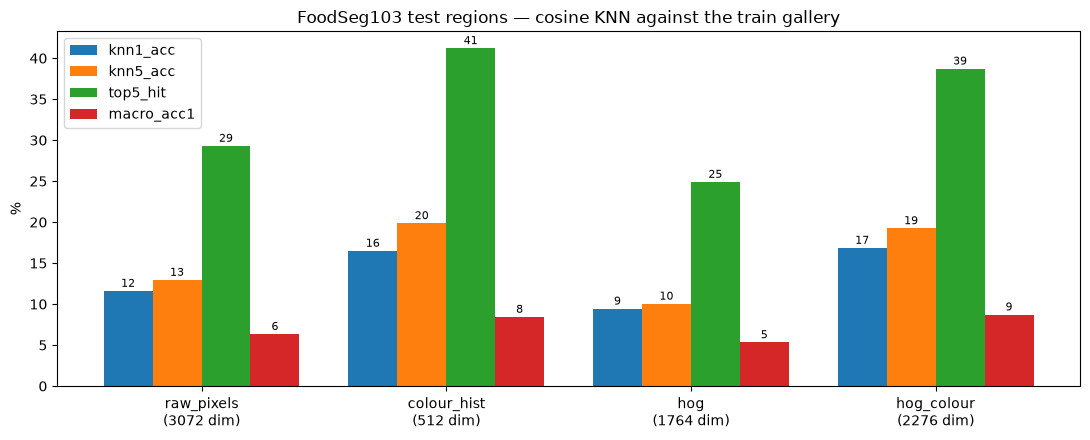

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.5))
metrics = ['knn1_acc', 'knn5_acc', 'top5_hit', 'macro_acc1']
w = 0.8 / len(metrics)
for k, met in enumerate(metrics):
    vals = results[met].astype(float).values * 100
    bars = ax.bar(np.arange(len(results)) + k * w, vals, w, label=met)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f'{v:.0f}', ha='center', fontsize=8)
ax.set_xticks(np.arange(len(results)) + w * (len(metrics) - 1) / 2,
              [f'{n}\n({int(d)} dim)' for n, d in zip(results.index, results['dim'])])
ax.set_ylabel('%'); ax.set_title('FoodSeg103 test regions — cosine KNN against the train gallery'); ax.legend()
plt.tight_layout(); plt.show()

## 7. Which foods does HOG + colour get right?

In [14]:
pc = pd.DataFrame(per_class['hog_colour']).T
pc['name'] = [NAMES[c] for c in pc.index]
pc = pc[pc['n'] >= 10].sort_values('acc')
print('Hardest classes (n >= 10 test regions):')
print(pc.head(10)[['name', 'n', 'acc']].to_string())
print('\nEasiest classes:')
print(pc.tail(10)[['name', 'n', 'acc']].to_string())

Hardest classes (n >= 10 test regions):
                      name     n  acc
71                  garlic  18.0  0.0
51                    lamb  18.0  0.0
101  white button mushroom  25.0  0.0
28                 avocado  16.0  0.0
56                  shrimp  25.0  0.0
61                   pizza  10.0  0.0
17                  almond  12.0  0.0
15                    milk  10.0  0.0
36                   peach  16.0  0.0
12               milkshake  21.0  0.0

Easiest classes:
             name      n       acc
48   chicken duck  184.0  0.233696
89  cilantro mint  128.0  0.242188
30     strawberry   90.0  0.244444
59           corn   84.0  0.285714
33      raspberry   13.0  0.307692
46          steak  164.0  0.310976
8       ice cream  135.0  0.325926
95    green beans   28.0  0.357143
32      blueberry   37.0  0.621622
87       broccoli  140.0  0.657143


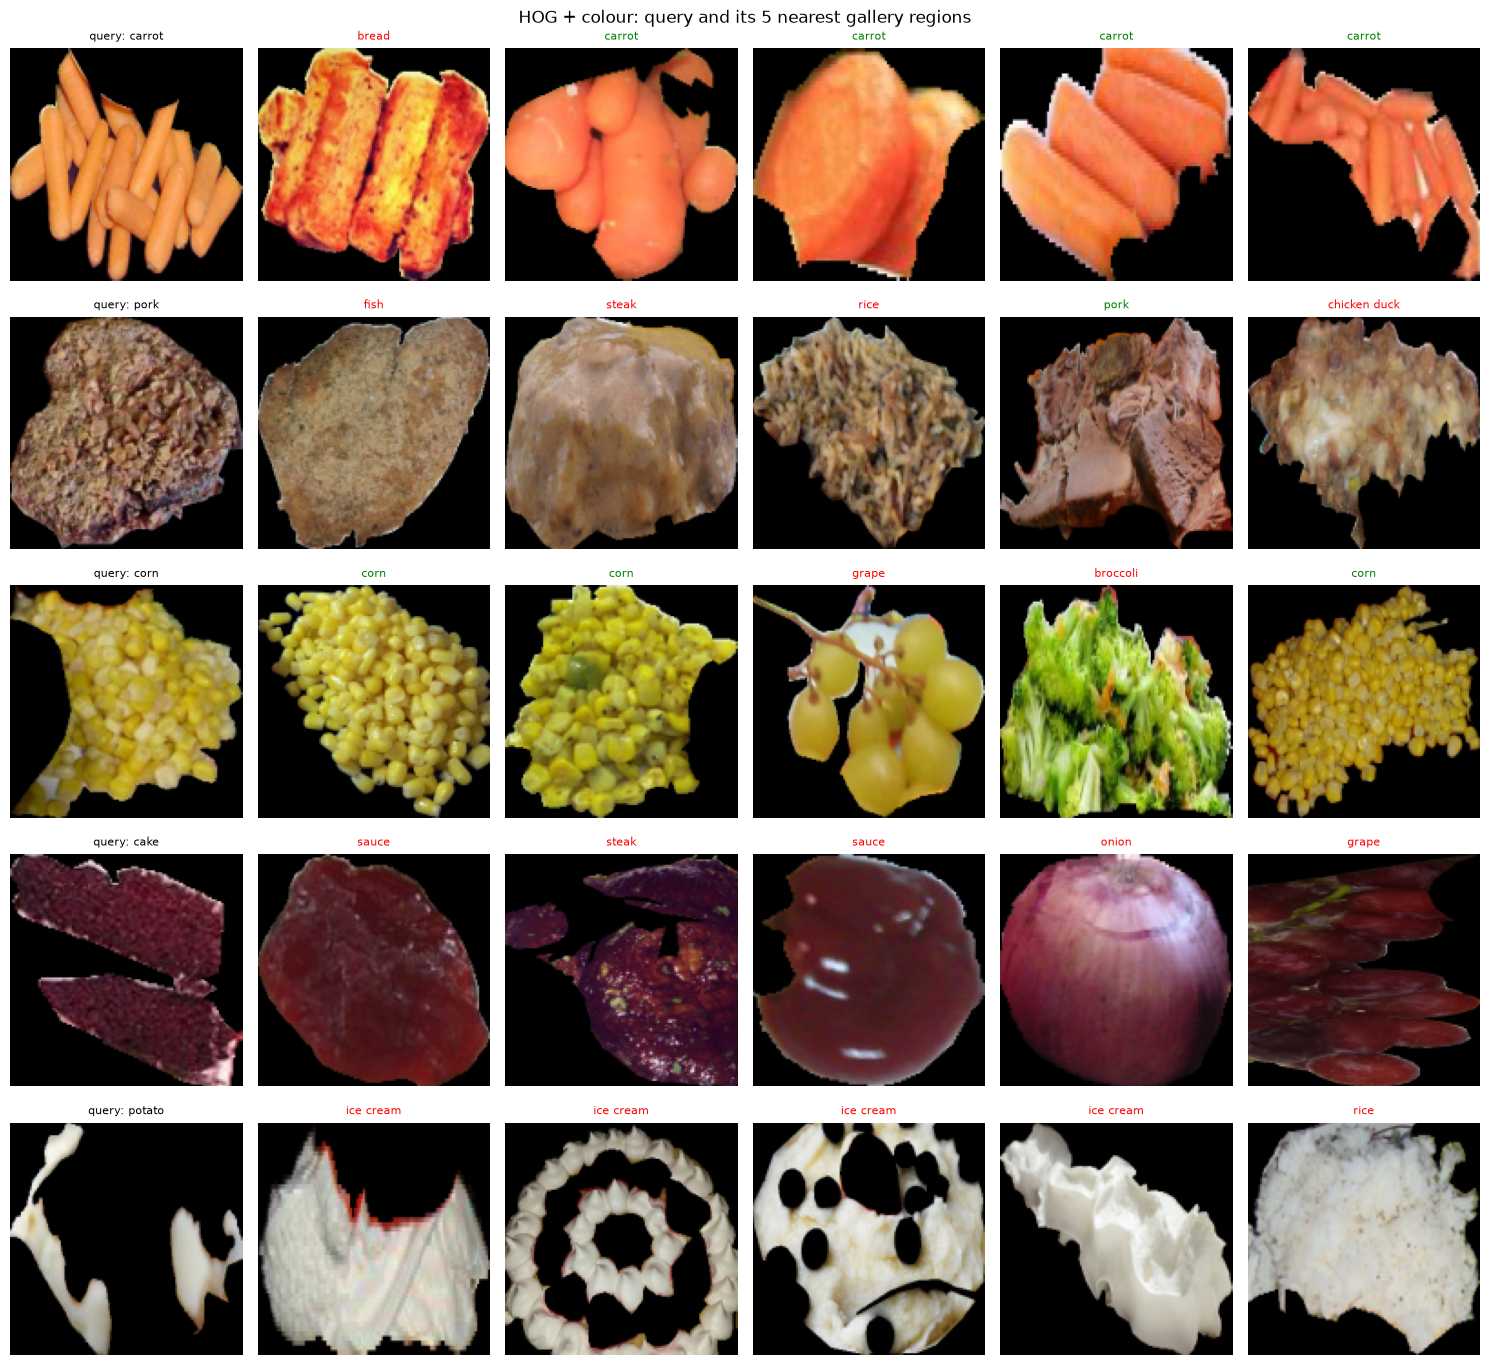

In [15]:
# Nearest-neighbour retrieval for a few test queries (green = same class as the query)
_, nn_idx = fe.knn_search(FEATURE_SPACES['hog_colour'][0], FEATURE_SPACES['hog_colour'][1], 5)
rng = np.random.default_rng(0)
qs = rng.choice(len(test_regions), size=5, replace=False)
q_crops = [next(fe.iter_crops('test', [test_regions[i]], CROP_SIZE))[1] for i in qs]
g_crop = lambda j: next(fe.iter_crops('train', [train_regions[j]], CROP_SIZE))[1]
fig, axes = plt.subplots(len(qs), 6, figsize=(15, 2.8 * len(qs)))
fe.show_retrievals(axes, q_crops, test_y[qs], g_crop, nn_idx[qs], train_y, NAMES)
plt.suptitle('HOG + colour: query and its 5 nearest gallery regions', fontsize=12)
plt.tight_layout(); plt.show()